In [15]:
from io import BytesIO
from pathlib import Path
import tarfile

from PIL import Image

In [16]:
archive_candidates = [
    Path("data/sportsmot_download/dataset/train.tar"),
    Path("../data/sportsmot_download/dataset/train.tar")
]

archive = next(
    (path for path in archive_candidates if path.exists()),
    None
)

if archive is None:
    raise FileNotFoundError("Could not find train.tar")

In [17]:
sequence = "train/v_-6Os86HzwCs_c001"

with tarfile.open(archive, "r") as tar:
    members = tar.getnames()

sequence_members = [
    name for name in members
    if name.startswith(sequence + "/img1/")
]

image_files = sorted([
    n for n in sequence_members
    if Path(n).suffix.lower() == ".jpg"
    and not Path(n).name.startswith("._")
])[:20]

print("Selected frames:", len(image_files))
print(image_files[:5])

Selected frames: 20
['train/v_-6Os86HzwCs_c001/img1/000001.jpg', 'train/v_-6Os86HzwCs_c001/img1/000002.jpg', 'train/v_-6Os86HzwCs_c001/img1/000003.jpg', 'train/v_-6Os86HzwCs_c001/img1/000004.jpg', 'train/v_-6Os86HzwCs_c001/img1/000005.jpg']


In [18]:
images = []

with tarfile.open(archive, "r") as tar:
    for name in image_files:
        f = tar.extractfile(name)

        if f is not None:
            image = Image.open(
                BytesIO(f.read())
            ).convert("RGB")

            images.append(image)

print(f"Loaded {len(images)} frames from {sequence}")

Loaded 20 frames from train/v_-6Os86HzwCs_c001


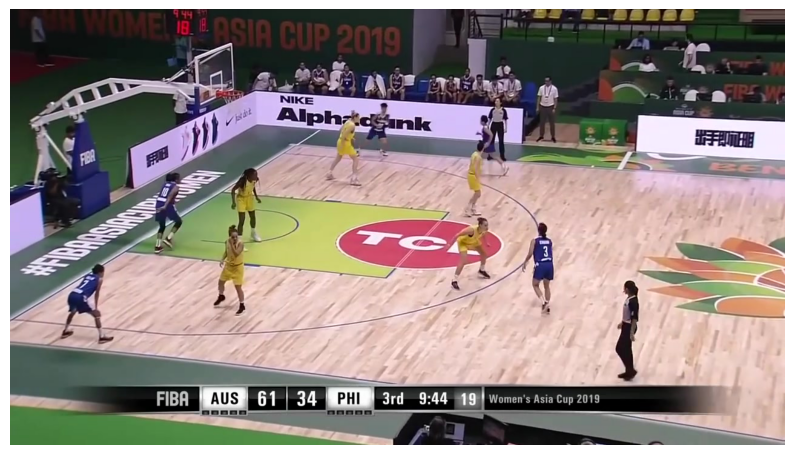

In [19]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.imshow(images[0])
plt.axis("off")
plt.show()

In [20]:
import io
import tarfile
import numpy as np

sequence = "train/v_-6Os86HzwCs_c001"

with tarfile.open(archive, "r") as tar:
    gt_bytes = tar.extractfile(
        f"{sequence}/gt/gt.txt"
    ).read()

gt = np.loadtxt(io.BytesIO(gt_bytes), delimiter=",")

In [21]:
print(gt.shape)
print(gt[:5])


(8074, 9)
[[  1.   0.  83. 421.  88. 130.   1.   1.   1.]
 [  1.   1. 335. 355.  54. 150.   1.   1.   1.]
 [  1.   2. 239. 269.  44. 135.   1.   1.   1.]
 [  1.   3. 366. 264.  48. 136.   1.   1.   1.]
 [  1.   4. 521. 167.  59. 124.   1.   1.   1.]]


IoU

In [22]:
print(np.unique(gt[:, 0])[:20])

[ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17. 18.
 19. 20.]


In [27]:
for name in image_files[:5]:
    print(Path(name).name)
frame_numbers = [int(Path(name).stem) for name in image_files]
print(frame_numbers)

000001.jpg
000002.jpg
000003.jpg
000004.jpg
000005.jpg
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]


In [28]:
print(frame_numbers[:10])
print(np.unique(gt[:, 0])[:10])

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
[ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10.]


In [29]:
frame_number = frame_numbers[0]

gt_frame = gt[gt[:, 0] == frame_number]

print("Frame number:", frame_number)
print("Ground-truth annotations:", len(gt_frame))

print("\nAnnotations:")
print(gt_frame)

Frame number: 1
Ground-truth annotations: 10

Annotations:
[[  1.   0.  83. 421.  88. 130.   1.   1.   1.]
 [  1.   1. 335. 355.  54. 150.   1.   1.   1.]
 [  1.   2. 239. 269.  44. 135.   1.   1.   1.]
 [  1.   3. 366. 264.  48. 136.   1.   1.   1.]
 [  1.   4. 521. 167.  59. 124.   1.   1.   1.]
 [  1.   5. 570. 155.  57.  89.   1.   1.   1.]
 [  1.   6. 769. 174.  55. 101.   1.   1.   1.]
 [  1.   7. 749. 217.  34. 125.   1.   1.   1.]
 [  1.   8. 721. 344.  71. 120.   1.   1.   1.]
 [  1.   9. 847. 352.  50. 151.   1.   1.   1.]]


 import the models


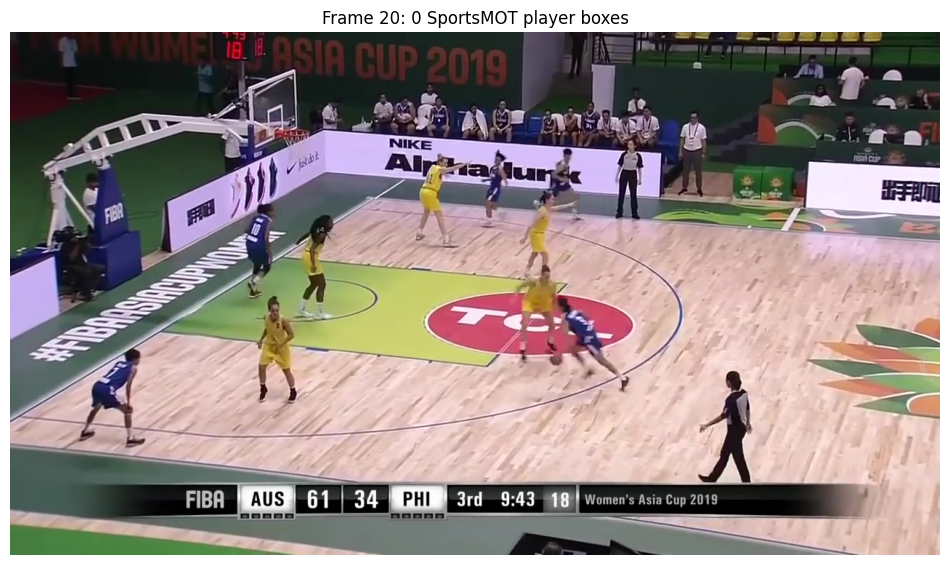

In [ ]:
import csv
from PIL import ImageDraw

# # The last loaded image is frame 20; read its SportsMOT ground-truth boxes.
frame_number = int(Path(image_files[-1]).stem)
# annotation_path = f"{sequence}/gt/gt.txt"
gt_bytes = gt[gt[:, 0] == frame_number]
# with tarfile.open(archive, "r") as tar:
#     annotation_file = tar.extractfile(annotation_path)
gt_bytes = [
        row for row in csv.reader(line.decode("utf-8") for line in annotation_file)
        if int(row[0]) == frame_number
    ]

boxed_frame = images[-1].copy()
draw = ImageDraw.Draw(boxed_frame)

for row in gt_bytes:
    _, track_id, left, top, width, height, *_ = map(float, row)
    right = left + width
    bottom = top + height
    draw.rectangle((left, top, right, bottom), 
                   outline="lime", width=3)
    draw.text((left, max(0, top - 14)), 
              f"ID {int(track_id)}", fill="lime", 
              stroke_width=1)

plt.figure(figsize=(12, 7))
plt.imshow(boxed_frame)
plt.title(f"Frame {frame_number}: {len(gt_bytes)} SportsMOT player boxes")
plt.axis("off")
plt.show()
